# D5 – Mini-projet : une série temporelle

**Python numérique – devoir n° 5 – à rendre pour le dimanche 18 octobre 2026, 23 h 59** (la séance 6 est le mardi 20)

Bienvenue dans votre cinquième devoir ! Nous allons y mettre en œuvre les notions vues en séance 5 : `to_datetime`, `DatetimeIndex`, la sélection par dates, `resample`, `rolling`, `df.plot` et les figures à plusieurs sous-graphiques avec `matplotlib`. C'est aussi un mini-projet : la dernière partie est ouverte, et c'est vous qui choisissez la question à laquelle répondre.

Durée indicative : 1 h 30.

````{admonition} Consignes de rendu
:class: important

* Ce notebook reste dans le dossier `D5/` de votre dépôt `pe-homework` (celui que le zip du sujet a créé en se dézippant), avec ses figures à côté, puis il doit être **commité et poussé** (`git add`, `git commit`, `git push`) avant la deadline. Attention, c'est la **date du commit** qui fait foi, pas celle du push ; le nom du fichier, lui, n'a pas d'importance (`sujet.ipynb` convient très bien). Le dossier `data/` livré avec le sujet reste lui aussi dans `D5/` : `git add D5` embarque tout le dossier, et c'est très bien ainsi (il ne pèse que quelques kilo-octets).
* Juste avant de rendre, **pensez à ré-exécuter toutes les cellules** via *Kernel → Restart Kernel and Run All Cells* : toutes doivent s'exécuter dans l'ordre et sans erreur. En effet, un notebook qui plante à mi-chemin sera corrigé jusqu'à l'erreur…
* Le notebook lit les données dans `data/comptage-velos.csv` (chemin relatif) ; la figure `serie.png` est quant à elle écrite dans le dossier du notebook.
* Les cellules `# votre code` sont à compléter ; vous pouvez ajouter autant de cellules que vous le souhaitez. Les cellules de test (`assert`) sont là pour vous aider : si elles passent sans erreur, c'est bon signe. Ne les modifiez pas !
* Répondez aux questions "en français" dans une cellule *Markdown*, en deux ou trois phrases. Dans ce devoir, la rédaction compte autant que le code.
````

````{admonition} Ce qui est autorisé
:class: note

* La documentation de `pandas` / `matplotlib`, les notebooks du cours, vos notes.
* Les assistants IA sont tolérés, avec la règle habituelle : **vous devez être capable d'expliquer chaque ligne que vous rendez**, et je pourrai vous demander de le faire à l'oral en séance. Le devoir est individuel.
* En revanche, pas de boucle `for` sur les lignes de la série : tout se fait avec les opérations `pandas`.
````

````{admonition} Les données
:class: warning

`data/comptage-velos.csv` contient le nombre de vélos comptés chaque jour par un compteur automatique installé sur une piste cyclable parisienne, du 1er janvier 2023 au 31 décembre 2024 : une colonne `date` (texte `AAAA-MM-JJ`) et une colonne `comptage`, séparées par `;`.

Attention, **ces données sont simulées** : je les ai produites avec le script `data/generate.py`, en fixant la graine afin que tout le monde travaille sur les mêmes valeurs. Vous pouvez le lire, mais seulement *après* avoir fait le devoir ! Elles ont cependant l'allure de vraies données de comptage, défauts compris : le fichier n'est pas trié, certaines lignes sont en double, certains jours n'ont pas de mesure, et le capteur a eu au moins deux ratés. Ainsi, comme dans la vraie vie, vous allez d'abord nettoyer, puis analyser.
````

## Barème

| Exercice | Contenu | Points |
|---|---|---|
| 1 | Chargement, index temporel, diagnostic et nettoyage | 6 |
| 2 | Rééchantillonnage (`resample`) et lissage (`rolling`) | 4 |
| 3 | Profils hebdomadaire et mensuel, 2023 vs 2024 | 4 |
| 4 | Figure à deux sous-graphiques `serie.png` | 3 |
| 5 | Question ouverte : une question, une figure, trois lignes de conclusion | 3 |
| **Total** | | **20** |
| Bonus | Jour le plus creux, croissance annuelle | +2 |

*Inspiré des exercices de <https://numerique-exos.info-mines.paris>.*

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Exercice 1 – Charger, indexer, nettoyer (6 pts)

**1.a** Lisez le fichier dans une `DataFrame` `df` et affichez `df.info()`. Quel est le type de la colonne `date` ? Pourquoi n'est-ce pas satisfaisant ? Le fichier est-il trié par date ?

In [2]:
# votre code
df = pd.read_csv('data/comptage-velos.csv',sep=';')
df.info()
print('le type de la colonne est string')
print('on veut un type qui reconnait le format des dates')
print('le fichier ne semble tout simplement non trié')

<class 'pandas.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      734 non-null    str    
 1   comptage  726 non-null    float64
dtypes: float64(1), str(1)
memory usage: 11.6 KB
le type de la colonne est string
on veut un type qui reconnait le format des dates
le fichier ne semble tout simplement non trié


In [3]:
assert df.shape == (734, 2)
assert list(df.columns) == ["date", "comptage"]
print("ok")

ok


**1.b** Construisez maintenant la `Series` `brut` : les comptages indexés par la date, avec un vrai `DatetimeIndex`, triée par date et en flottants.

In [4]:
# votre code
df['date']=pd.to_datetime(df['date'],format="%Y-%m-%d")
df=df.sort_values(by='date')
df.set_index('date')
brut=pd.Series(df['comptage'].values,index=df['date'])
brut

date
2023-01-01     304.0
2023-01-02    1658.0
2023-01-03    1450.0
2023-01-04    1902.0
2023-01-05    1715.0
               ...  
2024-12-27    1906.0
2024-12-28    1186.0
2024-12-29    1040.0
2024-12-30    1900.0
2024-12-31    2126.0
Length: 734, dtype: float64

In [5]:
assert isinstance(brut, pd.Series)
assert isinstance(brut.index, pd.DatetimeIndex)
assert brut.index.is_monotonic_increasing
assert len(brut) == 734
assert brut.index[0] == pd.Timestamp("2023-01-01") and brut.index[-1] == pd.Timestamp("2024-12-31")
print("ok")

ok


````{admonition} Pas encore vu en cours : duplicated()
:class: note

`serie.duplicated()` — ou `index.duplicated()` — renvoie un tableau de booléens de même longueur, avec `True` sur les valeurs *déjà rencontrées plus haut* : la première occurrence vaut `False`, les suivantes `True`. Ainsi, sur `[3, 1, 3, 3]`, on obtient `[False, False, True, True]`. Combiné à `~`, il permet donc de ne garder que la première occurrence de chaque valeur.
````

**1.c** Place au diagnostic. Répondez d'abord par du code, puis résumez vos observations dans une cellule Markdown :

* combien de dates apparaissent en double ? lesquelles ?
* combien de valeurs manquantes ? quels jours ?
* observez `brut.describe()` : le minimum et le maximum vous semblent-ils plausibles pour un compteur vélo ? Affichez les jours dont le comptage est nul, et ceux dont le comptage dépasse 3 fois la médiane.

In [6]:
# votre code
n=(brut.index.duplicated()).sum()
print(f'il y a {n} repetitions')
brut.index[brut.index.duplicated()]
print("les dates en doubles sont ['2023-05-25', '2023-12-21', '2024-02-27'] ")
print(f'il y a {brut.isna().sum()} valeur manquantes')
brut.index[brut.isna()]
print("les dates des valeurs manquantes sont ['2023-02-23', '2023-06-25', '2023-12-01', '2024-01-09','2024-02-08', '2024-03-13', '2024-11-17', '2024-11-22']")
display(brut.describe())
print('les estremums ne sont pas plausibles')
display(brut.index[brut==0])
brut.index[brut>3*brut.mean()]

il y a 3 repetitions
les dates en doubles sont ['2023-05-25', '2023-12-21', '2024-02-27'] 
il y a 8 valeur manquantes
les dates des valeurs manquantes sont ['2023-02-23', '2023-06-25', '2023-12-01', '2024-01-09','2024-02-08', '2024-03-13', '2024-11-17', '2024-11-22']


count      726.000000
mean      2454.612948
std       1646.281515
min          0.000000
25%       1770.250000
50%       2301.000000
75%       3090.000000
max      39660.000000
dtype: float64

les estremums ne sont pas plausibles


DatetimeIndex(['2024-06-27'], dtype='datetime64[us]', name='date', freq=None)

DatetimeIndex(['2024-07-04'], dtype='datetime64[us]', name='date', freq=None)

il y a 3 repetitions.
les dates en doubles sont '2023-05-25', '2023-12-21', '2024-02-27'
il y a 8 valeur manquantes.
les dates des valeurs manquantes sont '2023-02-23', '2023-06-25', '2023-12-01', '2024-01-09','2024-02-08', '2024-03-13', '2024-11-17', '2024-11-22'
les extremums ont des valeurs non plausibles (0 velos et presque 40k pour une moyenne a 2500.
les extremums sont atteint une seule fois, le '2024-06-27' pour le minimum et le '2024-07-04' pour le maximum.

In [7]:
assert brut.index.duplicated().sum() == 3
assert brut.isna().sum() == 8
assert (brut == 0).sum() == 1
assert (brut > 3 * brut.median()).sum() == 1
print("ok")

ok


````{admonition} Pas encore vu en cours : interpolate()
:class: note

`serie.interpolate()` remplace chaque `NaN` par une valeur déduite de ses voisins non manquants, par interpolation linéaire par défaut : sur `[10, NaN, NaN, 40]`, on obtient `[10, 20, 30, 40]`. C'est l'alternative à `fillna` quand les données ont un ordre naturel, comme ici le temps.
````

**1.d** Passons au nettoyage. Construisez la série propre `velos`, en trois temps :

1. supprimez les doublons d'index en ne gardant que la première occurrence (`duplicated()`) ;
2. remplacez les deux valeurs aberrantes (comptage nul ou supérieur à 3 fois la médiane) par `NaN` ;
3. remplissez tous les `NaN` (les 8 jours vides + les 2 aberrants) par interpolation linéaire.

Vérifiez enfin que `velos` a exactement une valeur par jour du 1er janvier 2023 au 31 décembre 2024 (soit 731 jours), et plus aucun `NaN`.

In [8]:
# votre code
velos=brut[~brut.index.duplicated()]
velos.loc['2024-06-27']=np.nan
velos.loc['2024-07-04']=np.nan
velos=velos.interpolate()
print(f'on a bien {velos.isna().sum()} nan et une shape de {velos.shape} tout est bon')

on a bien 0 nan et une shape de (731,) tout est bon


In [9]:
assert len(velos) == 731
assert velos.isna().sum() == 0
assert not velos.index.duplicated().any()
assert (velos.index == pd.date_range("2023-01-01", "2024-12-31", freq="D")).all()
assert velos.min() > 100 and velos.max() < 6000
assert abs(velos.loc["2024-07-04"] - (velos.loc["2024-07-03"] + velos.loc["2024-07-05"]) / 2) < 1
print("ok")

ok


## Exercice 2 – Rééchantillonner et lisser (4 pts)

**2.a** Calculez :

* `hebdo` : la moyenne par semaine ;
* `mensuel` : la moyenne par mois (l'alias de fréquence des mois est `"ME"`, *month end*, depuis pandas 2.2 ; `"M"` si votre pandas est plus ancien) ;
* `annuel` : le **total** par année.

Combien de lignes ont `hebdo` et `mensuel` ? Pourquoi `hebdo` n'a-t-il pas exactement 731 / 7 lignes ?

In [10]:
# votre code
d=velos.index
hebdo=velos.resample("W").mean()
mensuel=velos.resample("ME").mean()
annuel=velos.resample("YE").mean()
print(f'hebdo a {hebdo.shape} lignes, mensuel {mensuel.shape} lignes, annuel {annuel.shape} lignes')


hebdo a (106,) lignes, mensuel (24,) lignes, annuel (2,) lignes


In [11]:
assert len(hebdo) == 106 and len(mensuel) == 24 and len(annuel) == 2
assert abs(mensuel.sum() * 30.4 - velos.sum()) / velos.sum() < 0.05
assert annuel.iloc[1] > annuel.iloc[0]
print("ok")

ok


hebdo n'a pas 731/7 lignes car les semaine commencent a un jour fixé (exemple, on commence les semaines le lundi et pas notre tirage

**2.b** Calculez `lisse`, la moyenne glissante **centrée** sur 7 jours. Combien de `NaN` contient-elle, et où ? Pourquoi 7 jours est-il un bon choix de fenêtre pour cette série ? Enfin, tracez `velos` (trait fin, transparent) et `lisse` sur le même graphique, avec la méthode `.plot()` des `Series`.

elle contient 6 nan


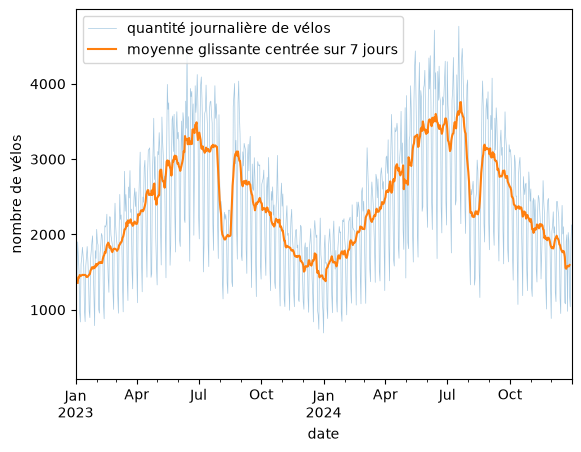

In [12]:
# votre code
lisse=velos.rolling(window=7,center=True).mean()
print(f'elle contient {lisse.isna().sum()} nan')
velos.plot(alpha=0.4,linewidth=0.5,label='quantité journalière de vélos')
lisse.plot(label='moyenne glissante centrée sur 7 jours')
plt.ylabel('nombre de vélos')
plt.legend();

**Une semaine dure 7 jours, d'ou l'interet de regrouper en semaine (nos vie admettent plus ou moins une periodicité de 7 jours)**

In [13]:
assert len(lisse) == 731
assert lisse.isna().sum() == 6
assert abs(lisse.loc["2023-06-15"] - velos.loc["2023-06-12":"2023-06-18"].mean()) < 1e-9
print("ok")

ok


## Exercice 3 – Profils (4 pts)

**3.a** Commençons par le profil hebdomadaire : calculez `profil_semaine`, la moyenne des comptages pour chaque jour de la semaine, avec 0 = lundi … 6 = dimanche. Remplacez ensuite l'index `0..6` par les noms des jours (`"lun"`, `"mar"`, … `"dim"`). De combien (en %) le dimanche est-il plus bas que la moyenne des jours de semaine (lundi à vendredi) ?

In [14]:
# votre code
profil_semaine=velos.groupby(d.dayofweek).mean()
profil_semaine.index=["lun","mar","mer","jeu","ven","sam","dim"]
dimanc=profil_semaine['dim']
moy=(profil_semaine.sum()-profil_semaine['dim'])/6
baisse=abs(moy-dimanc)/moy
baisse

np.float64(0.461873549500964)

In [15]:
assert profil_semaine.shape == (7,)
assert list(profil_semaine.index) == ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
assert profil_semaine["sam"] < 0.75 * profil_semaine["lun"]
assert profil_semaine["dim"] < profil_semaine["sam"]
print("ok")

ok


**la baisse est de 46%**

````{admonition} Pas encore vu en cours : idxmax et idxmin
:class: note

`serie.idxmax()` renvoie l'**étiquette** de la plus grande valeur (ici un numéro de mois), alors que `serie.max()` renvoie la valeur elle-même ; `idxmin` fait de même pour la plus petite. Sur une série indexée par des dates, on récupère donc directement le `Timestamp` du maximum.
````

**3.b** Intéressons-nous maintenant à la saisonnalité : calculez `profil_mois`, la moyenne pour chaque mois de l'année (1 à 12), les deux années confondues. Quel est le mois le plus chargé ? Et que se passe-t-il en août ?

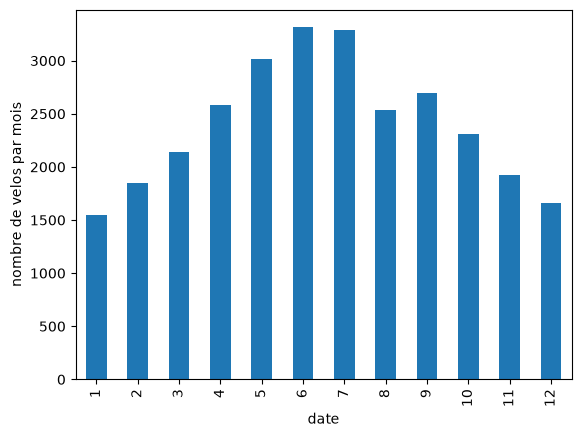

In [16]:
# votre code
profil_mois=velos.groupby(d.month).mean()
profil_mois.plot.bar()
plt.ylabel('nombre de velos par mois');

**en Aout les gens sont en vacances. Le mois le plus chargé est Juin**

In [17]:
assert profil_mois.shape == (12,) and list(profil_mois.index) == list(range(1, 13))
assert profil_mois.idxmax() in (6, 7)
assert profil_mois[8] < profil_mois[7] and profil_mois[8] < profil_mois[9]
assert profil_mois.idxmin() in (1, 12)
print("ok")

ok


**3.c** Opposons enfin 2023 à 2024 : avec la sélection par chaîne de date, calculez la moyenne journalière de chaque année, puis la croissance en % de 2023 à 2024 (variable `croissance`). Posez-vous ensuite la même question mois par mois : construisez la table `par_mois` de forme `(12, 2)` (lignes = mois, colonnes = années) — `unstack` peut aider — et repérez le mois où la progression a été la plus forte.

<Axes: xlabel='date'>

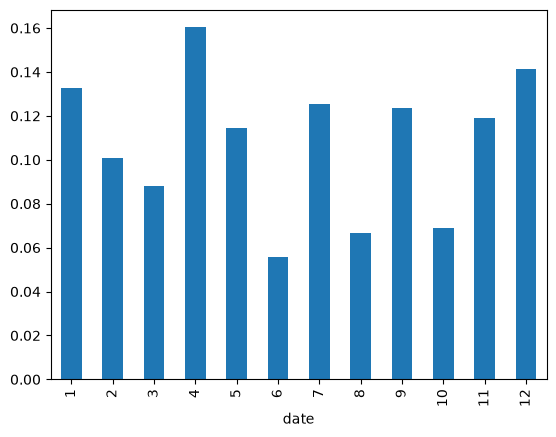

In [18]:
#votre code
y1=velos.loc[:"2023-12-31"].mean()
y2=velos.loc["2024-01-01":].mean()
croissance=(y2-y1)/y1*100
croissance
par_mois=velos.groupby([d.month,d.year]).mean()
par_mois=par_mois.unstack()
par_mois2=par_mois.copy()
par_mois2['croissance']=(abs(par_mois[2023]-par_mois[2024]))/par_mois[2023]
par_mois2['croissance'].plot.bar()

**la croissance est de 10.5% et elle a progressé le plus vite en avril**

In [19]:
assert 7 < croissance < 14
assert par_mois.shape == (12, 2)
assert list(par_mois.columns) == [2023, 2024]
assert (par_mois[2024] > par_mois[2023]).sum() >= 10
print("ok")

ok


## Exercice 4 – Figure à deux sous-graphiques (3 pts)

Construisez une figure `fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))` :

* en haut : la série journalière `velos` (trait fin, transparent) et la série lissée `lisse` (trait plus épais), avec une légende, un titre et un nom d'axe des ordonnées ;
* en bas : le profil hebdomadaire `profil_semaine` en barres, avec un titre et un nom d'axe des ordonnées.

Terminez par `fig.tight_layout()` et enregistrez dans `serie.png` (`fig.savefig`).

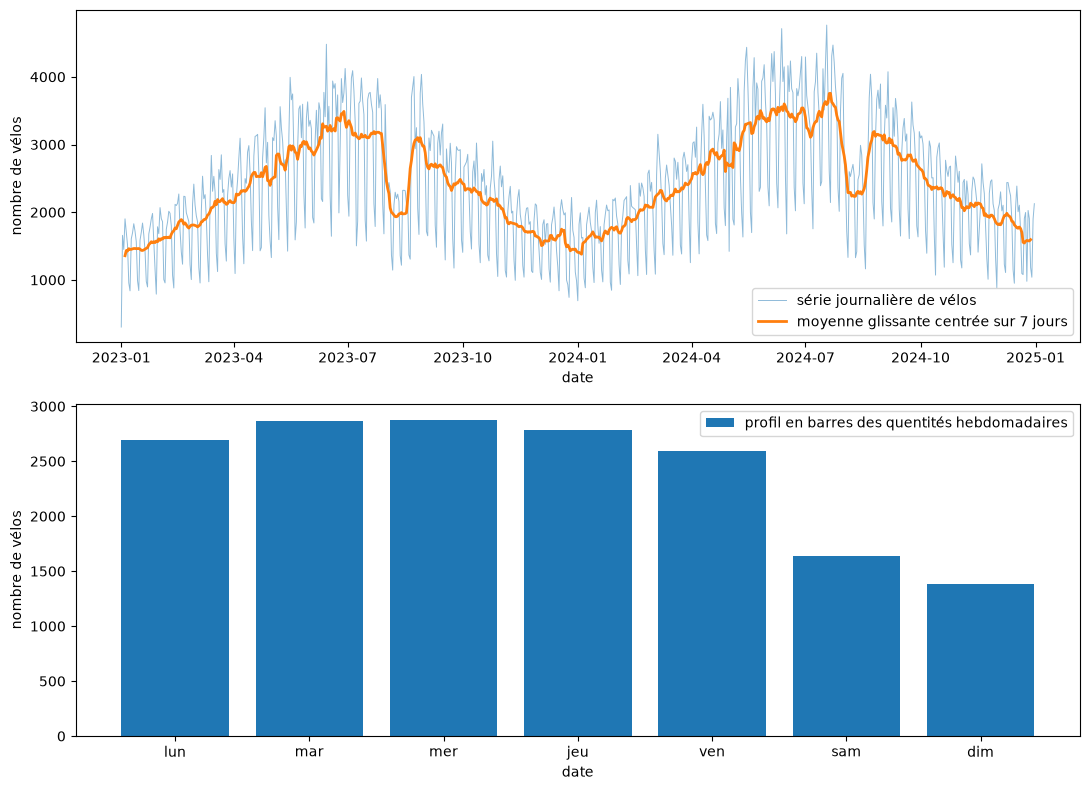

In [20]:
# votre code
fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))
ax_haut.plot(velos, linewidth=0.7, alpha=0.5, label="série journalière de vélos")
ax_haut.plot(lisse, linewidth=2, alpha=1, label="moyenne glissante centrée sur 7 jours")
ax_haut.legend()
ax_haut.set_ylabel("nombre de vélos")
ax_haut.set_xlabel("date")
ax_bas.bar(profil_semaine.index, profil_semaine.values, label="profil en barres des quentités hebdomadaires")
ax_bas.legend()
ax_bas.set_ylabel("nombre de vélos")
ax_bas.set_xlabel("date")
ax_bas.set_ylabel("nombre de vélos")
fig.tight_layout()
fig.savefig("serie.png")

In [21]:
assert os.path.exists("serie.png")
print("ok")

ok


## Exercice 5 – Question ouverte (3 pts)

C'est ici que vous prenez la main ! Choisissez **une** question sur cette série, puis répondez-y avec une figure (au moins une courbe ou un diagramme, légendée et titrée) et trois lignes de conclusion en Markdown. Voici quelques idées, mais une question à vous est la bienvenue :

* le creux d'août a-t-il la même ampleur en 2023 et en 2024 ?
* l'écart week-end / semaine est-il le même en été et en hiver ?
* quelle semaine de l'année est la plus chargée ? la plus creuse ? est-ce la même les deux années ?
* la croissance entre 2023 et 2024 est-elle uniforme sur l'année, ou concentrée sur certains mois ?
* que se passe-t-il autour des jours fériés que vous connaissez ?

Côté barème, je compte un point pour la pertinence de la méthode, un point pour une figure lisible et correcte, et un point pour une conclusion chiffrée et honnête.

date,2023,2024,croissance
mois,,,
jan,1451.612903,1644.000000,0.132533
fev,1755.160714,1931.741379,0.100607
mar,2053.516129,2234.532258,0.088149
avr,2393.466667,2777.133333,0.160297
mai,2849.903226,3176.096774,0.114458
juin,3223.133333,3403.233333,0.055877
juillet,3091.870968,3479.096774,0.125240
aout,2454.193548,2617.354839,0.066483
sep,2537.033333,2850.500000,0.123556


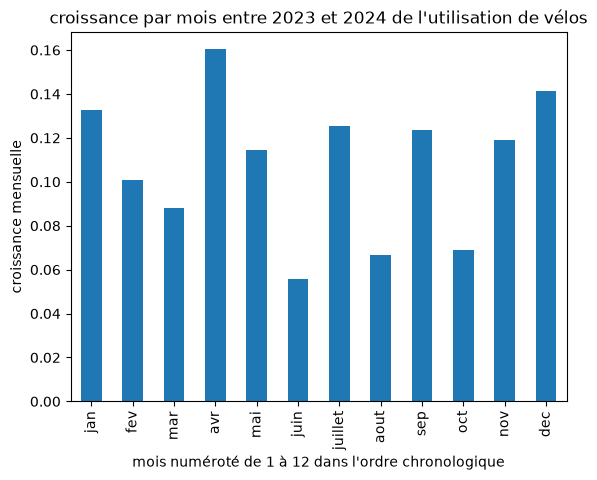

In [22]:
# votre code
y1=velos.loc[:"2023-12-31"].mean()
y2=velos.loc["2024-01-01":].mean()
croissance=(y2-y1)/y1*100
croissance
par_mois=velos.groupby([d.month,d.year]).mean()
par_mois=par_mois.unstack()
par_mois2=par_mois.copy()
par_mois2['croissance']=(abs(par_mois[2023]-par_mois[2024]))/par_mois[2023]
par_mois2['mois']=["jan","fev","mar","avr","mai","juin","juillet","aout","sep","oct","nov","dec"]
par_mois2=par_mois2.set_index('mois')
display(par_mois2)
par_mois2['croissance'].plot.bar()
plt.ylabel('croissance mensuelle')
plt.xlabel("mois numéroté de 1 à 12 dans l'ordre chronologique")
plt.title("croissance par mois entre 2023 et 2024 de l'utilisation de vélos");

**on observe de grandes différences entre les mois de l'année, on observe une croissance de moins de 6% en juin et de 16% en avril. On pourrait expliquer ces phénomènes par les variations de météo d'une année à l'autre, ce qui est facteur très important dans le choix du mode de transport: s'il fait trop chaud ou froid, on prefère prendre le métro!!**

## Bonus (+2)

**Bo.1** Quel est le jour le plus creux de toute la série ? Et le plus chargé ? Pour chacun, donnez le jour de la semaine (`.day_name()`) et proposez une explication.

````{admonition} Pas encore vu en cours : pct_change
:class: note

`serie.pct_change()` renvoie la variation *relative* d'une valeur à la suivante : sur `[100, 110, 99]`, elle donne `[NaN, 0.10, -0.10]`. La première case vaut `NaN` faute de valeur précédente, et le résultat est une proportion, à multiplier par 100 pour l'exprimer en pourcentage.
````

**Bo.2** Calculez la croissance annuelle en % à partir des totaux annuels `annuel`. Pourquoi ce chiffre est-il légèrement différent de `croissance` (exercice 3.c) ?

In [23]:
# votre code

Bon courage à tous ! Pour toute question sur le sujet, vous pouvez me contacter par email : [raphael@imagine-app.fr](mailto:raphael@imagine-app.fr).

Au plaisir de vous lire,

votre responsable de cours, Raphael Prasquier
(sujet conçu par Aurélien Noce)